<a href="https://colab.research.google.com/github/rymX/APIREST/blob/master/pneumoniaDetector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os #Used to interact with the operating system.
from glob import glob #glob is used to find files using patterns.
import matplotlib.pyplot as plt #display plots
import tensorflow as tf


In [22]:

from random import sample #randomly select elements from a list.
import sklearn.model_selection as skl #Train/test split  Cross validation

from tensorflow.keras.preprocessing.image import ImageDataGenerator #Data augmentation , Rescaling pixel values ,Loading images from folders
from keras.models import Sequential, Model #Two ways to build networks
from keras.applications.vgg16 import VGG16 #Pretrained CNN Models
from keras.applications.resnet import ResNet50 #Pretrained CNN Models
from keras.optimizers import Adam, RMSprop #Used to update model weights.
from keras.callbacks import ModelCheckpoint, LearningRateScheduler, EarlyStopping, ReduceLROnPlateau # prevent overfitting
from keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten, Conv2D, MaxPooling2D #build CNN architecture.
from tensorflow.keras.utils import plot_model

from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix #evaluation
import math


 **Doawnload** **dataset**

In [23]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nih-chest-xrays/data")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/nih-chest-xrays/data/versions/3


early processing

In [24]:

#lire tous les chemins d'accès complets de vos fichiers image dans un dataframe pour une manipulation plus aisée.
dataset_path = "/root/.cache/kagglehub/datasets/nih-chest-xrays/data/versions/3"
all_xray_df = pd.read_csv(os.path.join(dataset_path, "Data_Entry_2017.csv"))# Load metadata

all_image_paths = {
    os.path.basename(x): x
    for x in glob(os.path.join(dataset_path, "images*", "*", "*.png")) #Searches for all .png images ,

}
print("Scans found:", len(all_image_paths), ", Total Headers:", all_xray_df.shape[0])
#Number of actual images found = Number of rows in CSV

#This adds a new column
all_xray_df["path"] = all_xray_df["Image Index"].map(all_image_paths.get)


all_xray_df.sample(3)


Scans found: 112120 , Total Headers: 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
14405,00003736_000.png,No Finding,0,3736,57,M,PA,2992,2991,0.143,0.143,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
69180,00017070_003.png,No Finding,3,17070,61,M,AP,3056,2544,0.139,0.139,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
7753,00002034_000.png,No Finding,0,2034,48,F,PA,2500,2048,0.171,0.171,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...


afficher qlq data

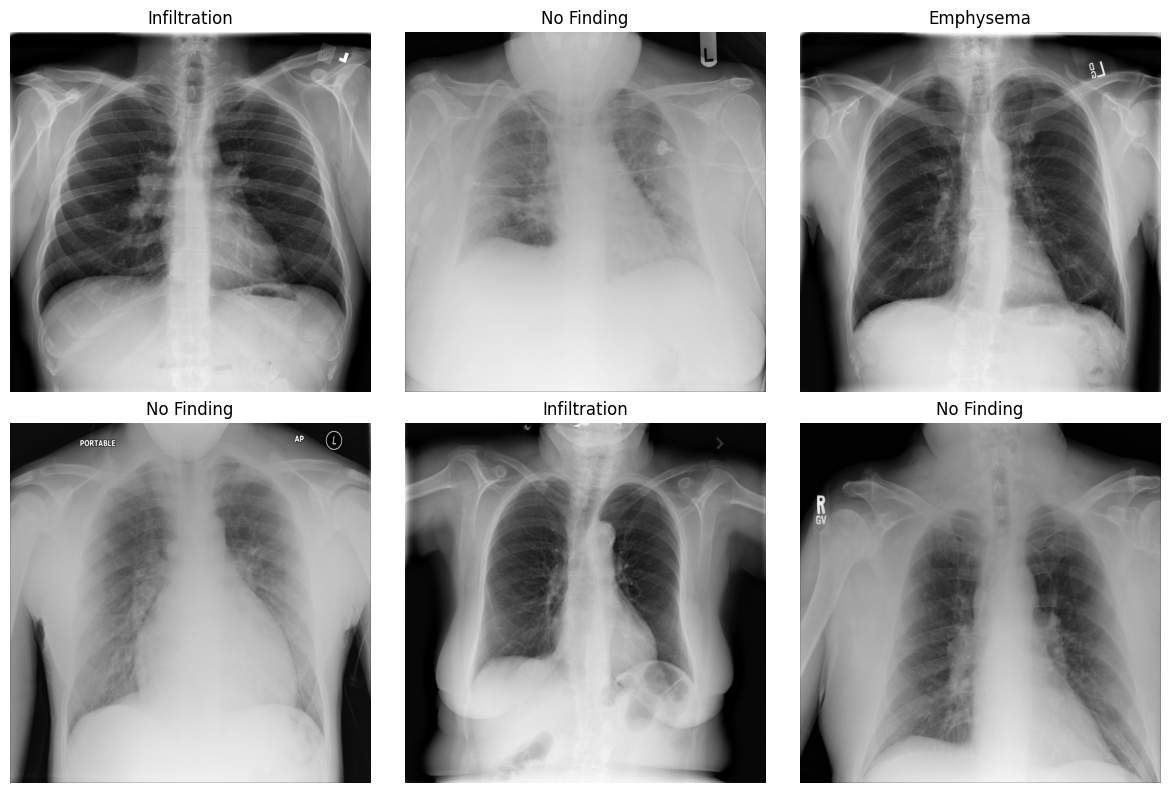

In [25]:
import matplotlib.image as mpimg
import random

sample_df = all_xray_df.dropna(subset=["path"]).sample(6)

plt.figure(figsize=(12,8))

for i, (_, row) in enumerate(sample_df.iterrows()):
    img = mpimg.imread(row["path"])

    plt.subplot(2,3,i+1)
    plt.imshow(img, cmap="gray")
    plt.title(row["Finding Labels"])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [26]:

#We need binary columns for each disease
## Here you may want to create some extra columns in your table with binary indicators of certain diseases
## rather than working directly with the 'Finding Labels' column
#ajouter colonnes supplémentaires dans  dataframe avec des indicateurs binaires de certaines maladies


findings = set()
for f in all_xray_df['Finding Labels'].unique():
    findings.update(f.split('|'))
print(f'Total number of single diagnoses: {len(findings)}')
findings

Total number of single diagnoses: 15


{'Atelectasis',
 'Cardiomegaly',
 'Consolidation',
 'Edema',
 'Effusion',
 'Emphysema',
 'Fibrosis',
 'Hernia',
 'Infiltration',
 'Mass',
 'No Finding',
 'Nodule',
 'Pleural_Thickening',
 'Pneumonia',
 'Pneumothorax'}

In [27]:
for finding in findings:
    all_xray_df[finding] = all_xray_df['Finding Labels'].map(lambda x: 1.0 if finding in x else 0)
all_xray_df.head(3)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,...,Hernia,Infiltration,Edema,Consolidation,Nodule,Pneumothorax,No Finding,Cardiomegaly,Pleural_Thickening,Mass
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [28]:
# Ici, nous pouvons créer une nouvelle colonne appelée « pneumonia_class » qui nous permettra d'examiner les
## images avec ou sans pneumonie pour une classification binaire


all_xray_df['pneumonia_class'] = all_xray_df.apply(lambda x: 'Y' if x['Pneumonia'] == 1.0 else 'N', axis=1)
all_xray_df.head(3)
#print(all_xray_df.columns)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,...,Infiltration,Edema,Consolidation,Nodule,Pneumothorax,No Finding,Cardiomegaly,Pleural_Thickening,Mass,pneumonia_class
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,N
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,N
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,N


In [29]:
def create_splits(**vargs):


    df = vargs['df']
    #80% train / 20% validation
    #Stratifié selon la « pneumonie_class » afin de préserver la proportion de cas de pneumonie
    train_df, valid_df = skl.train_test_split(df, test_size = 0.2, stratify = df['pneumonia_class'])

    #Affiche la proportion initiale de cas positifs dans le groupe d'entraînement/valide
    train_df_ratio = len(train_df[train_df['pneumonia_class'] == 'Y'])/len(train_df)
    valid_df_ratio = len(valid_df[valid_df['pneumonia_class'] == 'Y'])/len(valid_df)
    print(f'Initial split. Train set pneumonia: {100.0*train_df_ratio :.2f}%. Valid set pneumonia: {100.0*valid_df_ratio :.2f}%')

    # Faire en sorte que l'ensemble d'entraînement contienne le même nombre de cas positifs et négatifs.
    train_pos_inds = train_df[train_df['pneumonia_class'] == 'Y'].index.tolist()
    train_neg_inds = train_df[train_df['pneumonia_class'] == 'N'].index.tolist()

    train_neg_sample = sample(train_neg_inds, len(train_pos_inds))
    train_df = train_df.loc[train_pos_inds + train_neg_sample]

    train_df_ratio = len(train_df[train_df['pneumonia_class'] == 'Y'])/len(train_df)
    print(f'Train set corrected (50/50), pneumonia: {100.0*train_df_ratio :.2f}%')

    # Adjust validation set (20% positive / 80% negative)
    valid_pos_inds = valid_df[valid_df['pneumonia_class'] == 'Y'].index.tolist()
    valid_neg_inds = valid_df[valid_df['pneumonia_class'] == 'N'].index.tolist()

    valid_neg_sample = sample(valid_neg_inds, 4*len(valid_pos_inds))
    valid_df = valid_df.loc[valid_pos_inds + valid_neg_sample]

    valid_df_ratio = len(valid_df[valid_df['pneumonia_class'] == 'Y'])/len(valid_df)
    print(f'Valid set corrected (20/80), pneumonia: {100.0*valid_df_ratio :.2f}%')

    return train_df, valid_df

In [30]:
df_train, df_valid = create_splits(df = all_xray_df)
print(f'Train set size: {len(df_train)}, valid set size: {len(df_valid)}')

Initial split. Train set pneumonia: 1.28%. Valid set pneumonia: 1.28%
Train set corrected (50/50), pneumonia: 50.00%
Valid set corrected (20/80), pneumonia: 20.00%
Train set size: 2290, valid set size: 1430


 construction et l'entraînement de notre modèle.
Première etape: effectuez une augmentation de données

In [31]:
# most common image size used for augmentation
#Standard input size for VGG16 / ResNet50
IMAGE_SIZE = (224, 224)

def my_image_augmentation_train(**vargs):

  #small rotation, shift, zoom, horizontal flip

    rotation = vargs['rotation'] if 'rotation' in vargs else 20
    shear = vargs['shear'] if 'shear' in vargs else 0.1
    zoom = vargs['zoom'] if 'rotation' in vargs else 0.1

    gen = ImageDataGenerator(
        rescale=1. / 255.0,
        horizontal_flip = True,
        vertical_flip = False,
        height_shift_range = 0.1,
        width_shift_range = 0.1,
        rotation_range = rotation,
        shear_range = shear,
        zoom_range = zoom)

    return gen
#Create training generator
#Returns a Keras generator ready for model training
def make_train_gen(**vargs):



    df = vargs['df']

    aug = my_image_augmentation_train(**vargs)

    train_gen = aug.flow_from_dataframe(
        dataframe = df,
        directory = None,
        x_col = 'path',
        y_col = 'pneumonia_class',
        class_mode = 'binary',
        target_size = IMAGE_SIZE,
        batch_size = 16)#32

    return train_gen

#Validation augmentation , Only normalize pixel values (divide by 255)
def my_image_augmentation_valid(**vargs):


    gen = ImageDataGenerator(rescale=1. / 255.0)

    return gen
#Create validation generator
#Large batch size for validation → faster evaluation
def make_valid_gen(**vargs):

    df = vargs['df']

    aug = my_image_augmentation_valid(**vargs)

    valid_gen = aug.flow_from_dataframe(
        dataframe = df,
        directory = None,
        x_col = 'path',
        y_col = 'pneumonia_class',
        class_mode = 'binary',
        target_size = IMAGE_SIZE,
        batch_size = 256)#1024

    return valid_gen


In [32]:
train_gen = make_train_gen(df = df_train) #Outputs batches of images + binary Pneumonia labels
valid_gen = make_valid_gen(df = df_valid)

Found 2290 validated image filenames belonging to 2 classes.
Found 1430 validated image filenames belonging to 2 classes.


In [33]:
# prélever un seul lot important de données de validation aléatoires pour les tests après chaque époque :
valX, valY = next(valid_gen) #returns one batch of images and labels:

creation de modèle

Il est recommandé d’utiliser un réseau pré-entraîné téléchargé depuis Keras pour l’ajustement fin.

In [34]:
#Load pretrained VGG16
#load VGG16 for feature extraction (transfer learning).
#Charge VGG16 avec les couches supérieures entièrement connectées (include_top=True)

#weights='imagenet': pré-entraîné sur ImageNet

#Forme d'entrée : (224, 224, 3) par défaut

def load_pretrained_model(**vargs):

    model = VGG16(include_top=True, weights='imagenet')
    transfer_layer = model.get_layer('block5_pool') #block5_pool → last max-pooling layer in VGG16
    vgg_model = Model(inputs = model.input, outputs = transfer_layer.output) #Creates a new model (vgg_model) that outputs feature maps from block5_pool

    #Freezes the first 17 layers → weights will not update during training
    for layer in vgg_model.layers:
        layer.trainable = False
    #Print layers and trainable status
    print('VGG16 layers:')
    for layer in vgg_model.layers:
        print(layer.name, layer.trainable)
     #Return feature extractor
    return vgg_model

In [35]:
#Load pretrained VGG16
def build_my_model(**vargs):

    vgg_model = load_pretrained_model()
    #Build your classifier on top

    new_model = Sequential()
    new_model.add(vgg_model)

    new_model.add(Flatten()) #Flatten → converts feature maps to 1D vector
    new_model.add(Dropout(0.2)) #Dense layers + Dropout → your custom classifier
    new_model.add(Dense(1024, activation='relu'))
    new_model.add(Dropout(0.2))
    new_model.add(Dense(512, activation='relu'))
    new_model.add(Dropout(0.2))
    new_model.add(Dense(256, activation='relu'))
    new_model.add(Dropout(0.2))

    new_model.add(Dense(1, activation='sigmoid')) #binary classification

    return new_model

In [36]:
model = build_my_model()
model.summary()

VGG16 layers:
input_layer_2 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 False
block5_conv2 False
block5_conv3 False
block5_pool False


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_10 (Functional)      │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │    25,691,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,062,209 (156.64 MB)

 Trainable params: 26,347,521 (100.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [37]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Compile model (Keras 3 syntax)
optimizer = Adam(learning_rate=1e-4)
#configurer la manière dont le réseau va apprendre
#L’optimizer → comment les poids du modèle vont être mis à jour

#La fonction de perte (loss) → comment mesurer l’erreur

#Les métriques → comment évaluer la performance
model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)
#Sauvegarder les meilleurs poids du modèle dans ce fichier
weight_path = "xray_classification_model.weights.h5"
#est un callback qui sauvegarde automatiquement le modèle pendant l’entraînement.
checkpoint = ModelCheckpoint(
    weight_path,
    monitor='val_loss',
    mode='min',
    verbose=1,
    save_best_only=True,
    save_weights_only=True
)
#stops training to avoid overfitting
early = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=3,          # shorter patience for CPU
    restore_best_weights=True
)

callbacks_list = [checkpoint, early]

# Train model
history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=1,            # small number for CPU
    callbacks=callbacks_list,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - binary_accuracy: 0.5047 - loss: 0.7665 
Epoch 1: val_loss improved from inf to 0.90557, saving model to xray_classification_model.weights.h5
144/144 ━━━━━━━━━━━━━━━━━━━━ 2562s 18s/step - binary_accuracy: 0.5048 - loss: 0.7664 - val_binary_accuracy: 0.2014 - val_loss: 0.9056


In [48]:
import numpy as np
import requests
from PIL import Image
from io import BytesIO
from tensorflow.keras.applications.vgg16 import preprocess_input

def predict_from_url(image_url, model):

    # Télécharger l'image
    response = requests.get(image_url)
    img = Image.open(BytesIO(response.content)).convert("RGB")

    # Redimensionner (IMPORTANT : même taille que training)
    img = img.resize((224, 224))

    # Convertir en array
    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Preprocessing VGG16
    img_array = preprocess_input(img_array)

    # Prédiction
    prediction = model.predict(img_array)
    prob = prediction[0][0]

    if prob > 0.5:
        print(f" Pneumonia detected ({prob*100:.2f}%)")
    else:
        print(f"Normal ({(1-prob)*100:.2f}%)")

    return prob


In [49]:
image_url = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/1-s2.0-S0140673620303706-fx1_lrg.jpg"

predict_from_url(image_url, model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step
 Pneumonia detected (60.81%)


np.float32(0.6081016)